In [3]:
import math

class Val:
    def __init__(self, data,_op="", _operands=(), label=""):
        self.data = data
        self._prev = set(_operands)
        self._op = _op
        self._backward = lambda:None # the backprop mechanism: it knows how to propagate the gradient to the operands
        
        self.grad = 0.0 #how much does this particular node affect the final output;
        self.label = label
    def __repr__(self):
        return f"Value(data={self.data})"
    #exprs ( need to keep track of the dependencies for the result of these exprs)
    def __add__(self, other):
        other = other if isinstance(other, Val) else Val(other) 
        add = Val(self.data+  other.data,"+", (self, other))
        def _backward(): 
            self.grad += 1.0 * add.grad # the rate of chnage for this particular opn is going to be 1 but we also gotta take into account the running gradient and therefore we multiply (CHAIN RULE)
            other.grad += 1.0 * add.grad
            #>> setting the gradient for the operands: a+ b =c -> u knw that dc/da =1 , dc/db =1;

            # we set the gradient for the operands at the time the operationn is done
        add._backward = _backward
        
        return add
        
    def __mul__(self, other):
        other =other if isinstance(other,Val) else Val(other) 

        mul = Val(self.data * other.data, "*", (self, other) )
        def _backward():
            self.grad += other.data * mul.grad
            other.grad += self.data * mul.grad
          
        mul._backward = _backward
        
        return mul
    def __rmul__(self,other):
        return self * other

    def __truediv__(self,other):
        return self * other**-1

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only int/float"
        out=Val(self.data**other, f'**{other}' ,(self,))

        def _backward():
            self.grad += other* (self.data**(other -1)) * out.grad
        out._backward = _backward
        return out
        
    def tanh(self): #it's our activation func. , it keeps the output b/w -1to1;
        x=self.data
        t=(math.exp(2*x) -1 )/(math.exp(2*x)+1)
        out = Val(t, "tanh", (self,))  

        def _backward():
            self.grad = (1 - t**2) * out.grad
        out._backward = _backward
        return out

    def exp(self):
        x = self.data
        out = Val(math.exp(x),  'exp', (self, ))

        def _backward():
            self.grad += out.data * out.grad
            # local derivative * current running grad
        out._backward = _backward
        return out

    def __neg__(self):
        return self * -1
    def __radd__(self, other):
        return self + other

    def __sub__(self,other):
        other = other if isinstance(other, Val) else Val(other) 
        return self +(-other)
        
    def backward(self):#backpropagation.
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
              
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        
        self.grad=1
        for node in reversed(topo):
            node._backward()
                

        

In [4]:
# dobut: why do we need the activation function at all? what purpose does it serve? what if we don't have it?

In [5]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f}" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      # print("Operation:", repr(n._op), type(n._op))
      dot.node(name = str(uid) + str(n._op), label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot


In [6]:
a = Val(2, label='a')
b = Val(-3,label='b')
c = Val(4, label='c')
e = a*b; e.label='e'
d = e+c; d.label='d'
f = Val(-2.0, label ='f')
L = d * f; L.label = "L"
O=L.tanh()
O.label="O"

In [7]:
# # draw_dot(O)
O.backward()


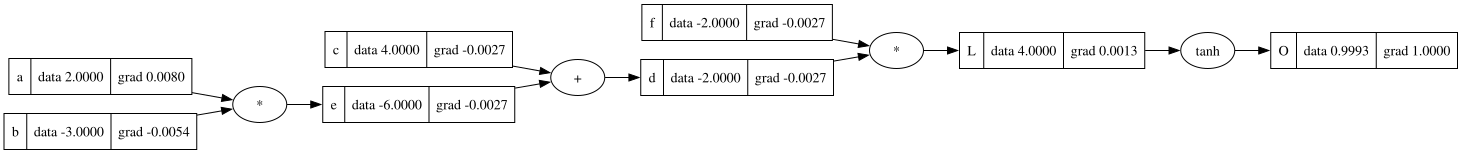

In [8]:
draw_dot(O)

In [9]:
import random
class Neuron:
    def __init__(self, nin):#nin: no. of inputs into the neuron. and each input will have a weight associated with it that we will manipulate to tune the loss:
        self.w = [Val(random.uniform(-1,1)) for _ in range(nin)]# we don't change the inputs we only change the weights for those inputs;
        self.b = Val(random.uniform(-1,1))

    def __call__(self, x):
        # wx + b => for each input to the neuron we have a weight and multiplying it together to get the activation.
        # why do wx+b though why not wx**2 +b?
        summ = [wi*xi for wi,xi in zip(self.w, x)] 
        act=Val(0)
        for i in summ:
            act+=i
        act+=self.b
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outs= [n(x) for n in self.neurons]
        return outs[0] if len(outs)==1 else outs

    def parameters(self):
        params = []
        for neuron in self.neurons:
            ps = neuron.parameters()
            params.extend(ps)
        return params
class MLP: # combining the layers 
    def __init__(self, nin, nouts):
        # nin: Number of input features the network receives.
        # nouts: A list specifying the number of neurons in each layer.
        sz = [nin]+nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x):
        for layer in self.layers:
            x=layer(x)
        return x
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
        




In [70]:

x =[2.0, 3.0,  -1.0]
n=MLP(3, [4,4,1])


In [71]:
#tiny dataset:
xv = [
    [1.0, -3.2, 4.7, 9.2],
    [3.2, -4.62, -3.7, -1.2],
    [1.0, 8.2, 4.7, -3.5],
    [8.0, -8.2, 4.6, 1.2],
]
yv = [1.0, -1.0, -1.0, 1.0]



In [94]:
for j in range(300):
    #forward passs
    yo = [n(inp) for inp in xv]
    loss = sum([(ypred - yog)**2 for yog, ypred in zip(yv, yo)])

    #backprop
    for p in n.parameters():
        p.grad=0.0
    loss.backward()

    # grad. desc.
    for p in n.parameters():
        p.data += -0.05 * p.grad # moving in the opposite value of the gradient to reduce the loss 



    # print(f"{j}: {loss.data}")


In [95]:
yo


[Value(data=0.9910229362080047),
 Value(data=-0.9872553653598205),
 Value(data=-0.9949733749862922),
 Value(data=0.9909274137185501)]